In [4]:
from IPython.display import display, Markdown
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
import scipy.stats

ModuleNotFoundError: No module named 'seaborn'

In [3]:
filepath = 'data/audioData.csv'
audioData = pd.read_csv(filepath)

# columns_with_all_zeros = audioData.columns[audioData.eq(0).all()]

# # Print the column names with all zeros
# for col_name in columns_with_all_zeros:
#     print(f"Column '{col_name}' has all values equal to 0.")
pitchAverages = audioData[audioData != 0].mean(axis=0)
pitchAverages = pitchAverages.reset_index(drop=False)
pitchAverages.columns = ['Clip_ID', 'pitchAverage']
# DROP 0 VALUES 
pitchAverages = pitchAverages[pitchAverages['Clip_ID'] != 'cut_feb2203-human-20']
pitchAverages = pitchAverages[pitchAverages['Clip_ID'] != 'cut_feb2803-human-13']
# print("Column Averages (excluding 0s):")
# print(pitchAverages)

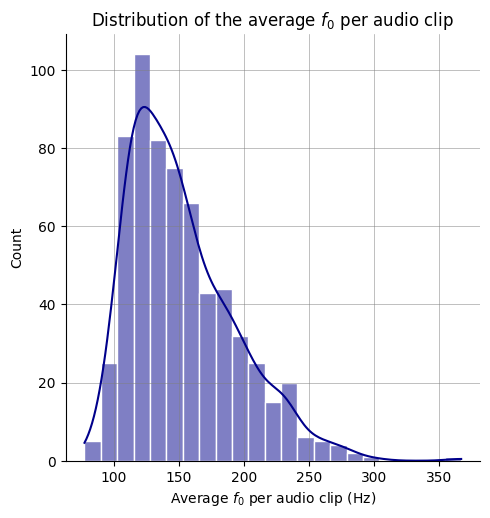

In [4]:
plot = sns.displot(pitchAverages['pitchAverage'], kde=True, kind='hist', color="darkblue")
plot.set_axis_labels(r"Average $f_{0}$ per audio clip (Hz)", "Count")
plot.set(title=r"Distribution of the average $f_{0}$ per audio clip")
plot.ax.xaxis.grid(True, linewidth=0.5, color='gray', alpha=0.7)
plot.ax.yaxis.grid(True, linewidth=0.5, color='gray', alpha=0.7)
for ax in plot.axes.flat:
    for bar in ax.patches:
        bar.set_edgecolor("white")


In [5]:
%run ./dataManipulation.ipynb

In [6]:
bigFive = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
data = pd.DataFrame(medianScoresPerClip(), columns=['Clip_ID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness'])
pitchWithFeaturesAv = pd.merge(pitchAverages, data, on='Clip_ID')


In [7]:
metadata = pd.read_csv('data/metadata.csv')

sexId = metadata.loc[:,['Clip_ID', 'Gender']].copy()
mergedDfAv = pd.merge(pitchWithFeaturesAv, sexId, on='Clip_ID')

femaleOnlyAv = mergedDfAv[mergedDfAv['Gender'] == 'F']
maleOnlyAv = mergedDfAv[mergedDfAv['Gender'] == 'M']

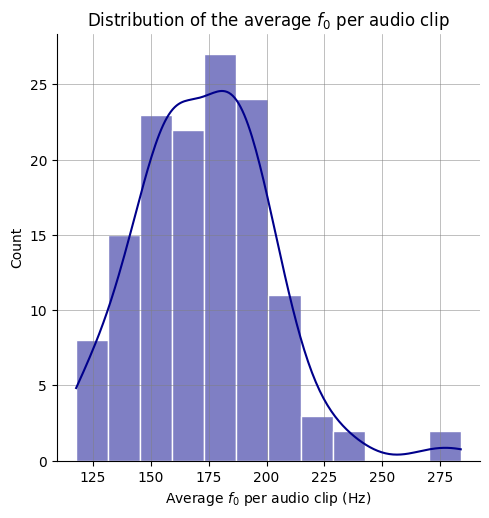

In [9]:
plot = sns.displot(femaleOnlyAv['pitchAverage'], kde=True, kind='hist', color="darkblue")

plot.set_axis_labels(r"Average $f_{0}$ per audio clip (Hz)", "Count")
plot.set(title=r"Distribution of the average $f_{0}$ per audio clip")
plot.ax.xaxis.grid(True, linewidth=0.5, color='gray', alpha=0.7)
plot.ax.yaxis.grid(True, linewidth=0.5, color='gray', alpha=0.7)
for ax in plot.axes.flat:
    for bar in ax.patches:
        bar.set_edgecolor("white")


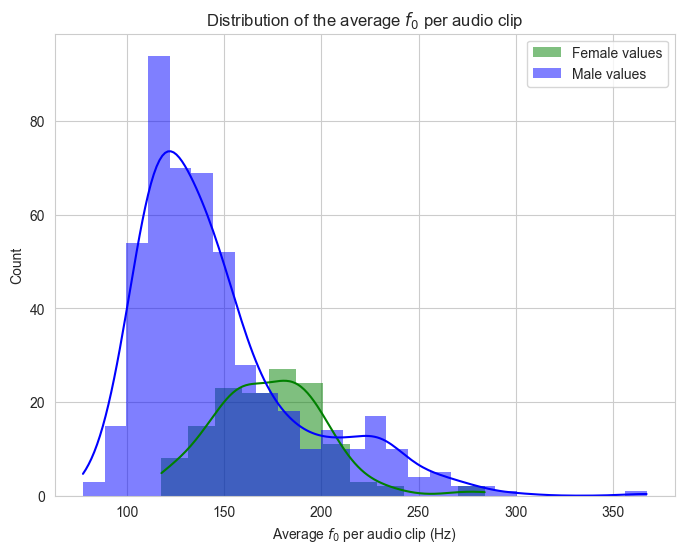

In [19]:
sns.set_style('whitegrid')
plt.figure(figsize=(8, 6))  
sns.histplot(femaleOnlyAv['pitchAverage'], color="green", label="Female values", kde=True, linewidth=0, alpha=0.5)
sns.histplot(maleOnlyAv['pitchAverage'], color="blue", label="Male values", kde=True, linewidth=0, alpha=0.5)
plt.xlabel(r"Average $f_{0}$ per audio clip (Hz)")
plt.ylabel("Count")
plt.title(r"Distribution of the average $f_{0}$ per audio clip")
plt.legend()
plt.show()

In [22]:
# T TEST to see the difference between the pitch for female and male

tStatistic, pValue = scipy.stats.ttest_ind(a=femaleOnlyAv['pitchAverage'], b=maleOnlyAv['pitchAverage'], equal_var=True)
result = [tStatistic, pValue]
print(result)

[7.091917143715987, 3.5332355718679572e-12]


In [23]:
data = [[femaleOnlyAv['pitchAverage'].mean(), femaleOnlyAv['pitchAverage'].min(), femaleOnlyAv['pitchAverage'].max(), np.std(femaleOnlyAv['pitchAverage'])], [maleOnlyAv['pitchAverage'].mean(), maleOnlyAv['pitchAverage'].min(), maleOnlyAv['pitchAverage'].max(), np.std(maleOnlyAv['pitchAverage'])]]
dfPitchInfo = pd.DataFrame(data, columns=['Mean f_0', 'Minimum f_0', 'Maximum f_0', 'st. dev'], index=['Female', 'Male'])
dfPitchInfo

,Mean f_0,Minimum f_0,Maximum f_0,st. dev
Female,173.450310,117.656982,283.996488,28.437971
Male,146.466992,77.286834,367.320230,41.903651


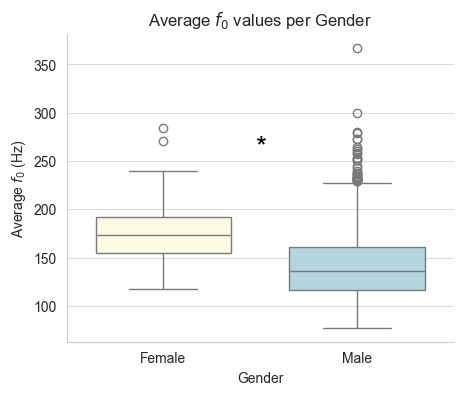

In [41]:
labels = ['Female'] * len(femaleOnlyAv['pitchAverage']) + ['Male'] * len(maleOnlyAv['pitchAverage'])
df = np.concatenate((femaleOnlyAv['pitchAverage'],maleOnlyAv['pitchAverage']),axis=0)
df = pd.DataFrame({'f_0': df, 'Gender' : labels})

tStatistic, pValue = scipy.stats.ttest_ind(a=femaleOnlyAv['pitchAverage'], b=maleOnlyAv['pitchAverage'], equal_var=True)

star = ''
if (pValue < 0.05):
    star = '*'

plt.figure(figsize=(5, 4))
box = sns.boxplot(x='Gender', y='f_0', hue='Gender', data=df, legend=False, width=0.7, palette=['lightyellow','lightblue'])

plt.text(0.5, 250, star, ha='center', va='bottom', color='black', fontsize=20)

plt.title(r'Average $f_0$ values per Gender')
plt.ylabel(r'Average $f_0$ (Hz)')
plt.grid(axis='y', alpha=0.7)
sns.despine()
plt.show()

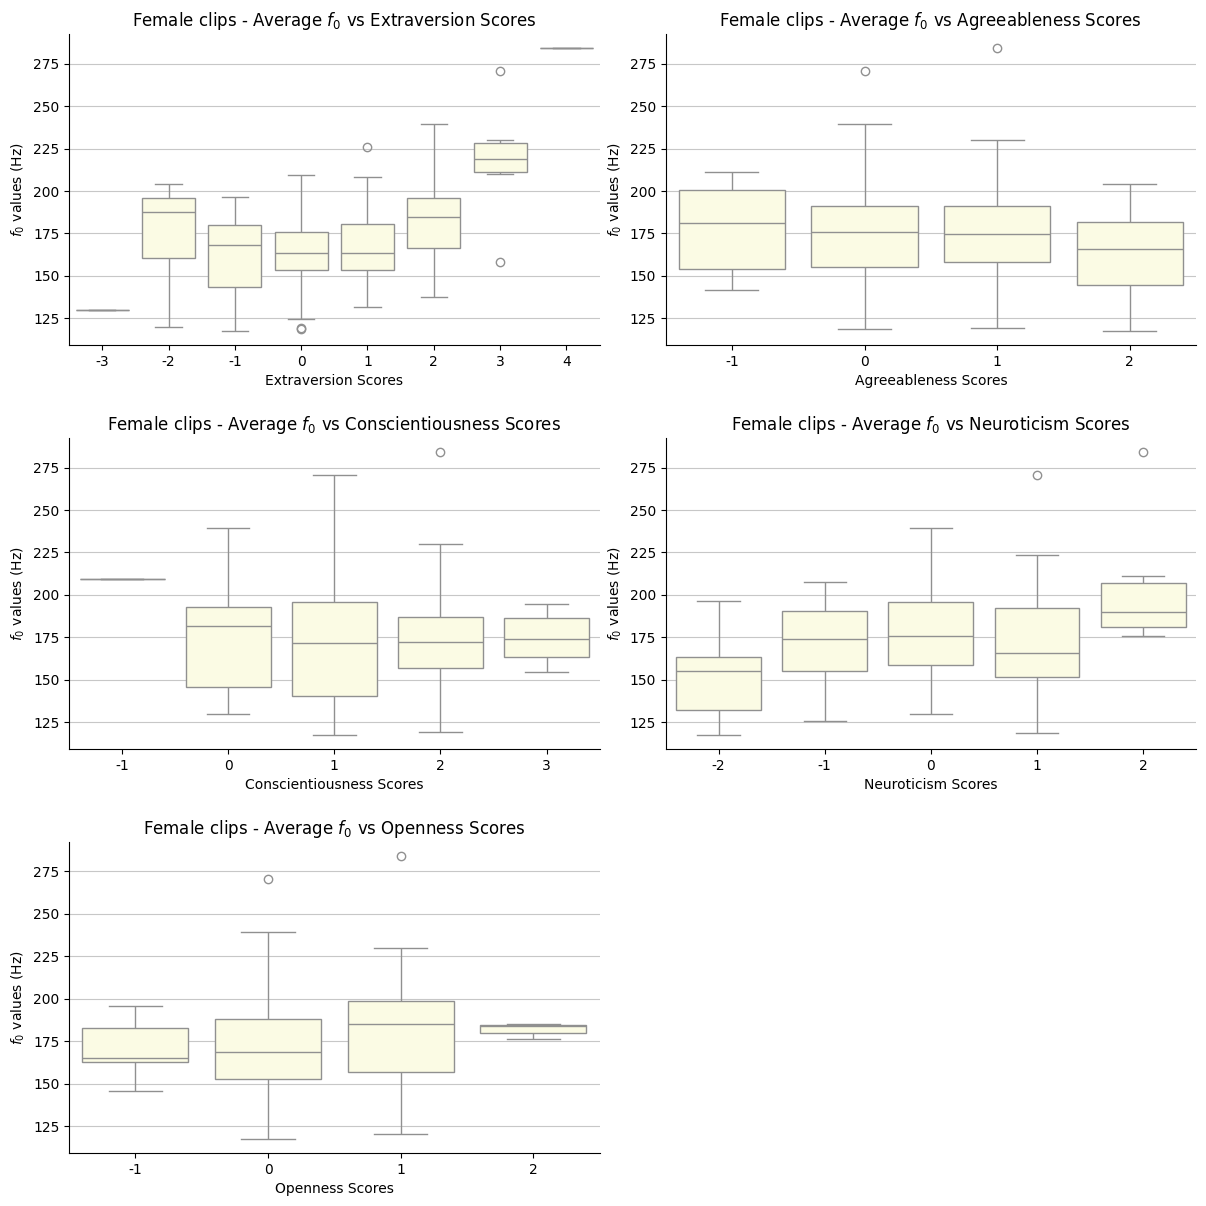

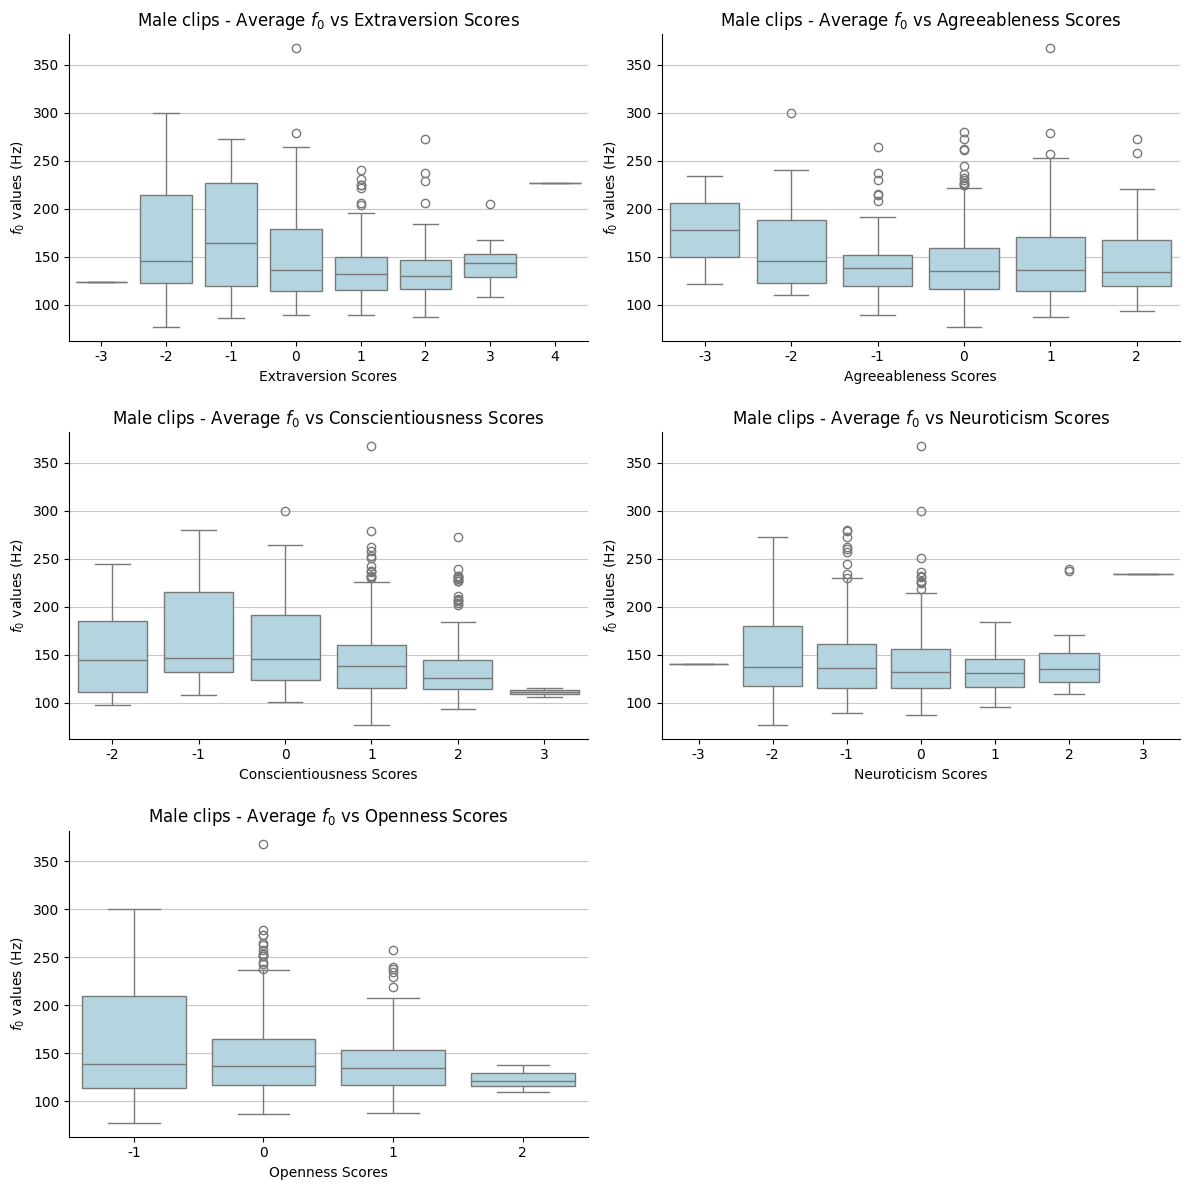

In [56]:

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 12))
axes = axes.flatten()

for index, (trait, ax) in enumerate(zip(bigFive, axes)):
    pitchData = femaleOnlyAv['pitchAverage']
    traitScores = femaleOnlyAv[trait]
    df = pd.DataFrame({f'{trait} Scores': traitScores, 'f_0 values': pitchData})

    sns.boxplot(x=f'{trait} Scores', y='f_0 values', data=df, ax=ax,color = "lightyellow")
    ax.set_title(r'Female clips - Average $f_0$ ' + f'vs {trait} Scores')

    ax.grid(axis='y', alpha=0.7)
    sns.despine()

    ax.set_xlabel(f'{trait} Scores')
    ax.set_ylabel(r'$f_0$ values (Hz)')

plt.delaxes()
plt.tight_layout(pad=0.5)
plt.subplots_adjust(hspace=0.3)
plt.show()


fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 12))
axes = axes.flatten()

for index, (trait, ax) in enumerate(zip(bigFive, axes)):
    pitchData = maleOnlyAv['pitchAverage']
    traitScores = maleOnlyAv[trait]
    df = pd.DataFrame({f'{trait} Scores': traitScores, 'f_0 values': pitchData})

    sns.boxplot(x=f'{trait} Scores', y='f_0 values', data=df, ax=ax, color="lightblue")
    ax.set_title(r'Male clips - Average $f_0$ ' + f'vs {trait} Scores')

    ax.grid(axis='y', alpha=0.7)
    sns.despine()
    ax.set_xlabel(f'{trait} Scores')
    ax.set_ylabel(r'$f_0$ values (Hz)')

plt.delaxes()
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)
plt.show()

In [255]:
# display(Markdown('## Female Average pitch vs trait'))
# for trait in bigFive:    
#     plt.scatter(femaleOnlyAv['pitchAverage'], femaleOnlyAv[trait], s=10)
#     plt.xlabel(r'Average $f_0$ (Hz)')
#     plt.ylabel(trait)
#     plt.title(r'Female clips - Average $f_0$ ' + f'vs {trait} Scores')
#     plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
#     plt.show()
    
# display(Markdown('## Male Average pitcqh vs trait'))
# for trait in bigFive:    
#     plt.scatter(maleOnlyAv['pitchAverage'], maleOnlyAv[trait], s=10)
#     plt.xlabel(r'Average $f_0$ (Hz)')
#     plt.ylabel(trait)
#     plt.title(r'Male clips - Average $f_0$ ' + f'vs {trait} Scores')
#     plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
#     plt.show()



In [254]:
display(Markdown('## Female Average Pitch'))
femaleCorrelations = pd.DataFrame(index=bigFive, columns=['rho', 'p'])
for trait in bigFive:
    rho, p = spearmanr(femaleOnlyAv['pitchAverage'], femaleOnlyAv[trait])
    femaleCorrelations.loc[trait] = [rho, p]

display(femaleCorrelations)

display(Markdown('## Male Average Pitch'))
maleCorrelations = pd.DataFrame(index=bigFive, columns=['rho', 'p'])
for trait in bigFive:
    rho, p = spearmanr(maleOnlyAv['pitchAverage'],maleOnlyAv[trait])
    maleCorrelations.loc[trait] = [rho, p]

display(maleCorrelations)


## Female Average Pitch

,rho,p
Extraversion,0.299961,0.000369
Agreeableness,-0.108466,0.207071
Conscientiousness,-0.008762,0.919055
Neuroticism,0.270054,0.001416
Openness,0.159689,0.062327


## Male Average Pitch

,rho,p
Extraversion,-0.166116,0.000188
Agreeableness,-0.00446,0.920685
Conscientiousness,-0.217335,0.000001
Neuroticism,-0.071829,0.108316
Openness,-0.040626,0.364172
